# UCS420 Lab Assignment 10 — NLP using Python-II
**Feature extraction from text, sentiment analysis and text generation**

**Name:** Aman Jha
**Roll No.:** 1024170215

In [1]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

import re
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

---
## Q1. Text preprocessing on my own paragraph
Topic: **Cricket**

In [2]:
paragraph = (
    "Cricket is more than just a sport in India; it is a festival that unites millions of fans. "
    "I have been playing gully cricket with my friends since I was eight years old, and those evening matches are my favourite memories. "
    "Test cricket teaches patience, while the T20 format rewards bold strokes and quick thinking. "
    "Watching Virat Kohli chase a difficult target under pressure inspires me to stay calm during my own exams. "
    "The 2011 World Cup final, when Dhoni finished the game with a six, is still the greatest moment I've ever watched on TV! "
    "Whether it's a packed stadium or a dusty street, the sound of bat hitting ball always makes me smile."
)
print(paragraph)

Cricket is more than just a sport in India; it is a festival that unites millions of fans. I have been playing gully cricket with my friends since I was eight years old, and those evening matches are my favourite memories. Test cricket teaches patience, while the T20 format rewards bold strokes and quick thinking. Watching Virat Kohli chase a difficult target under pressure inspires me to stay calm during my own exams. The 2011 World Cup final, when Dhoni finished the game with a six, is still the greatest moment I've ever watched on TV! Whether it's a packed stadium or a dusty street, the sound of bat hitting ball always makes me smile.


### 1. Lowercase and remove punctuation using `re`

In [3]:
lower = paragraph.lower()
clean = re.sub(r"[^\w\s]", "", lower)   # drop everything that is not a word char or whitespace
print(clean)

cricket is more than just a sport in india it is a festival that unites millions of fans i have been playing gully cricket with my friends since i was eight years old and those evening matches are my favourite memories test cricket teaches patience while the t20 format rewards bold strokes and quick thinking watching virat kohli chase a difficult target under pressure inspires me to stay calm during my own exams the 2011 world cup final when dhoni finished the game with a six is still the greatest moment ive ever watched on tv whether its a packed stadium or a dusty street the sound of bat hitting ball always makes me smile


### 2. Tokenize into sentences and words

In [4]:
sentences = sent_tokenize(paragraph)          # sentence tokenization needs the original punctuation
words = word_tokenize(clean)
print(f"{len(sentences)} sentences:")
for i, s in enumerate(sentences, 1):
    print(f"  {i}. {s}")
print(f"\n{len(words)} word tokens:\n{words}")

6 sentences:
  1. Cricket is more than just a sport in India; it is a festival that unites millions of fans.
  2. I have been playing gully cricket with my friends since I was eight years old, and those evening matches are my favourite memories.
  3. Test cricket teaches patience, while the T20 format rewards bold strokes and quick thinking.
  4. Watching Virat Kohli chase a difficult target under pressure inspires me to stay calm during my own exams.
  5. The 2011 World Cup final, when Dhoni finished the game with a six, is still the greatest moment I've ever watched on TV!
  6. Whether it's a packed stadium or a dusty street, the sound of bat hitting ball always makes me smile.

115 word tokens:
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'festival', 'that', 'unites', 'millions', 'of', 'fans', 'i', 'have', 'been', 'playing', 'gully', 'cricket', 'with', 'my', 'friends', 'since', 'i', 'was', 'eight', 'years', 'old', 'and', 'those', 'evening',

### 3. `split()` vs `word_tokenize()`

In [5]:
sample = sentences[4]       # the World Cup sentence has an apostrophe, a comma and '!'
split_tokens = sample.split()
nltk_tokens = word_tokenize(sample)
print("Sentence       :", sample)
print(f"str.split()    ({len(split_tokens)}):", split_tokens)
print(f"word_tokenize  ({len(nltk_tokens)}):", nltk_tokens)
print("\nOnly in split()      :", sorted(set(split_tokens) - set(nltk_tokens)))
print("Only in word_tokenize:", sorted(set(nltk_tokens) - set(split_tokens)))
print(f"\nWhole paragraph -> split(): {len(paragraph.split())} tokens, word_tokenize(): {len(word_tokenize(paragraph))} tokens")

Sentence       : The 2011 World Cup final, when Dhoni finished the game with a six, is still the greatest moment I've ever watched on TV!
str.split()    (23): ['The', '2011', 'World', 'Cup', 'final,', 'when', 'Dhoni', 'finished', 'the', 'game', 'with', 'a', 'six,', 'is', 'still', 'the', 'greatest', 'moment', "I've", 'ever', 'watched', 'on', 'TV!']
word_tokenize  (27): ['The', '2011', 'World', 'Cup', 'final', ',', 'when', 'Dhoni', 'finished', 'the', 'game', 'with', 'a', 'six', ',', 'is', 'still', 'the', 'greatest', 'moment', 'I', "'ve", 'ever', 'watched', 'on', 'TV', '!']

Only in split()      : ["I've", 'TV!', 'final,', 'six,']
Only in word_tokenize: ['!', "'ve", ',', 'I', 'TV', 'final', 'six']

Whole paragraph -> split(): 115 tokens, word_tokenize(): 129 tokens


**Difference:** `str.split()` only breaks on whitespace, so punctuation stays glued to words (`final,`, `TV!`, `I've`).
`word_tokenize()` uses the Penn Treebank rules: it separates punctuation into its own tokens (`,` `!`) and splits
contractions (`I've` → `I` + `'ve`, `it's` → `it` + `'s`). That is why NLTK produces more tokens and cleaner words for later steps.

### 4. Remove stopwords

In [6]:
filtered = [w for w in words if w not in STOP]
print(f"Before: {len(words)} tokens   After: {len(filtered)} tokens")
print(filtered)

Before: 115 tokens   After: 68 tokens
['cricket', 'sport', 'india', 'festival', 'unites', 'millions', 'fans', 'playing', 'gully', 'cricket', 'friends', 'since', 'eight', 'years', 'old', 'evening', 'matches', 'favourite', 'memories', 'test', 'cricket', 'teaches', 'patience', 't20', 'format', 'rewards', 'bold', 'strokes', 'quick', 'thinking', 'watching', 'virat', 'kohli', 'chase', 'difficult', 'target', 'pressure', 'inspires', 'stay', 'calm', 'exams', '2011', 'world', 'cup', 'final', 'dhoni', 'finished', 'game', 'six', 'still', 'greatest', 'moment', 'ive', 'ever', 'watched', 'tv', 'whether', 'packed', 'stadium', 'dusty', 'street', 'sound', 'bat', 'hitting', 'ball', 'always', 'makes', 'smile']


### 5. Word frequency distribution (excluding stopwords)

[('cricket', 3), ('sport', 1), ('india', 1), ('festival', 1), ('unites', 1), ('millions', 1), ('fans', 1), ('playing', 1), ('gully', 1), ('friends', 1)]


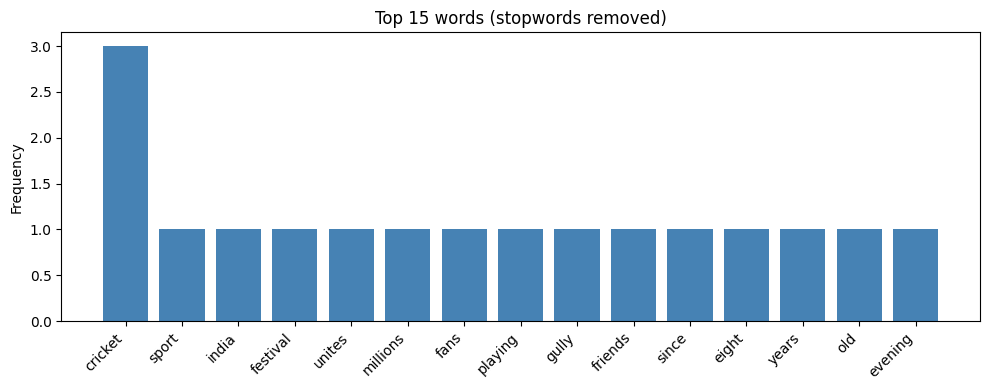

In [7]:
from nltk import FreqDist
fdist = FreqDist(filtered)
print(fdist.most_common(10))

top = fdist.most_common(15)
plt.figure(figsize=(10, 4))
plt.bar([w for w, _ in top], [c for _, c in top], color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.title("Top 15 words (stopwords removed)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

---
## Q2. Stemming vs Lemmatization (same paragraph)

In [8]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. only alphabetic words
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print(f"1. Alphabetic words ({len(alpha_words)}):\n{alpha_words}\n")

# 2. remove stopwords
alpha_nostop = [w for w in alpha_words if w not in STOP]
print(f"2. After stopword removal ({len(alpha_nostop)}):\n{alpha_nostop}\n")

# 3. stemming  4. lemmatization
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed = [stemmer.stem(w) for w in alpha_nostop]
lemma_n = [lemmatizer.lemmatize(w) for w in alpha_nostop]              # default POS = noun
lemma_v = [lemmatizer.lemmatize(w, pos="v") for w in alpha_nostop]     # treat as verb
print("3. Stemmed       :", stemmed, "\n")
print("4. Lemmatized (n):", lemma_n)

1. Alphabetic words (115):
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'festival', 'that', 'unites', 'millions', 'of', 'fans', 'i', 'have', 'been', 'playing', 'gully', 'cricket', 'with', 'my', 'friends', 'since', 'i', 'was', 'eight', 'years', 'old', 'and', 'those', 'evening', 'matches', 'are', 'my', 'favourite', 'memories', 'test', 'cricket', 'teaches', 'patience', 'while', 'the', 'format', 'rewards', 'bold', 'strokes', 'and', 'quick', 'thinking', 'watching', 'virat', 'kohli', 'chase', 'a', 'difficult', 'target', 'under', 'pressure', 'inspires', 'me', 'to', 'stay', 'calm', 'during', 'my', 'own', 'exams', 'the', 'world', 'cup', 'final', 'when', 'dhoni', 'finished', 'the', 'game', 'with', 'a', 'six', 'is', 'still', 'the', 'greatest', 'moment', 'i', 've', 'ever', 'watched', 'on', 'tv', 'whether', 'it', 's', 'a', 'packed', 'stadium', 'or', 'a', 'dusty', 'street', 'the', 'sound', 'of', 'bat', 'hitting', 'ball', 'always', 'makes', 'me', 'smile']

2

### 5. Comparison

In [9]:
import pandas as pd
cmp = pd.DataFrame({"word": alpha_nostop, "porter_stem": stemmed,
                    "lemma (noun)": lemma_n, "lemma (verb)": lemma_v}).drop_duplicates("word")
diff = cmp[(cmp["porter_stem"] != cmp["lemma (noun)"]) | (cmp["lemma (noun)"] != cmp["lemma (verb)"])]
print(diff.to_string(index=False))

     word porter_stem lemma (noun) lemma (verb)
 festival      festiv     festival     festival
   unites        unit       unites        unite
 millions     million      million     millions
  playing        play      playing         play
    gully       gulli        gully        gully
  friends      friend       friend      friends
    since        sinc        since        since
    years        year         year        years
  evening        even      evening         even
favourite    favourit    favourite    favourite
 memories      memori       memory     memories
 patience     patienc     patience     patience
 thinking       think     thinking        think
 watching       watch     watching        watch
 pressure     pressur     pressure     pressure
 inspires      inspir     inspires      inspire
    exams        exam         exam        exams
 finished      finish     finished       finish
  watched       watch      watched        watch
   packed        pack       packed      

**Observations**
- The Porter stemmer chops suffixes by rule, so it often produces non-words: `memories → memori`, `festival → festiv`, `since → sinc`, `pressure → pressur`, `dusty → dusti`. It can also wrongly merge words (`evening → even`).
- The WordNet lemmatizer returns real dictionary words (`memories → memory`, `fans → fan`, `matches → match`). With the correct POS tag it also handles verbs (`playing → play`, `watched → watch`, `inspires → inspire`). Without a POS tag it treats everything as a noun and leaves verbs unchanged.

**When to prefer which**
- **Stemming:** when speed and recall matter more than readability, e.g. search engines, information retrieval, or quick bag-of-words features on large corpora. Merging word variants roughly is good enough there.
- **Lemmatization:** when the output must be meaningful or meaning matters, e.g. chatbots, question answering, sentiment analysis, or any text shown to users. It is slower and works best with POS tags, but it gives valid words and fewer wrong merges.

---
## Q3. Bag of Words and TF-IDF on 3 short texts (product reviews)

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "The new smartphone has an amazing camera and the battery easily lasts two full days.",
    "The laptop keyboard feels cheap and the battery drains within three hours of light use.",
    "These wireless earbuds deliver deep bass, clear calls and a comfortable fit for long workouts.",
]
labels = ["Phone review", "Laptop review", "Earbuds review"]

# 1. Bag of Words
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=labels)
print("Bag of Words matrix:")
bow_df

Bag of Words matrix:


,amazing,bass,battery,calls,camera,cheap,clear,comfortable,days,deep,...,keyboard,laptop,lasts,light,long,new,smartphone,use,wireless,workouts
Phone review,1,0,1,0,1,0,0,0,1,0,...,0,0,1,0,0,1,1,0,0,0
Laptop review,0,0,1,0,0,1,0,0,0,0,...,1,1,0,1,0,0,0,1,0,0
Earbuds review,0,1,0,1,0,0,1,1,0,1,...,0,0,0,0,1,0,0,0,1,1


In [11]:
# 2. TF-IDF
tfv = TfidfVectorizer(stop_words="english")
tfidf = tfv.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tfv.get_feature_names_out(), index=labels).round(3)
print("TF-IDF matrix:")
tfidf_df

TF-IDF matrix:


,amazing,bass,battery,calls,camera,cheap,clear,comfortable,days,deep,...,keyboard,laptop,lasts,light,long,new,smartphone,use,wireless,workouts
Phone review,0.363,0.000,0.276,0.000,0.363,0.000,0.000,0.000,0.363,0.000,...,0.000,0.000,0.363,0.000,0.000,0.363,0.363,0.000,0.000,0.000
Laptop review,0.000,0.000,0.260,0.000,0.000,0.341,0.000,0.000,0.000,0.000,...,0.341,0.341,0.000,0.341,0.000,0.000,0.000,0.341,0.000,0.000
Earbuds review,0.000,0.302,0.000,0.302,0.000,0.000,0.302,0.302,0.000,0.302,...,0.000,0.000,0.000,0.000,0.302,0.000,0.000,0.000,0.302,0.302


In [12]:
# 3. Top 3 keywords per text
for label, row in tfidf_df.iterrows():
    top3 = row.sort_values(ascending=False).head(3)
    print(f"{label:15s}: " + ", ".join(f"{w} ({s:.3f})" for w, s in top3.items()))
print("\n'battery' idf =", round(tfv.idf_[tfv.vocabulary_['battery']], 3),
      " vs unique word idf =", round(tfv.idf_.max(), 3))

Phone review   : amazing (0.363), days (0.363), camera (0.363)
Laptop review  : cheap (0.341), feels (0.341), drains (0.341)
Earbuds review : bass (0.302), clear (0.302), calls (0.302)

'battery' idf = 1.288  vs unique word idf = 1.693


**Interpretation**
- BoW only counts words. Every non-stopword in these short texts appears once, so BoW cannot tell which word matters most.
- TF-IDF lowers the weight of words that appear in several documents. `battery` occurs in both the phone and laptop reviews, so its IDF (and score) is lower than words found in only one review.
- The top keywords therefore describe what makes each review different. The phone review gets *amazing, days, camera*, the laptop review *cheap, feels, drains*, and the earbuds review *bass, clear, calls*. Scores in the earbuds review are lower overall (0.302) because it has more unique words, so after L2 normalisation each word gets a smaller share. Ties are broken alphabetically because each word occurs once, but in every case a keyword unique to that review scores above the shared word `battery`.

---
## Q4. Jaccard vs Cosine similarity: AI vs Blockchain

In [13]:
from nltk.stem import WordNetLemmatizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = (
    "Artificial intelligence enables computers to learn patterns from large amounts of data. "
    "Machine learning models are trained on data to make predictions and decisions. "
    "Deep learning uses neural networks with many layers to recognise images and speech. "
    "AI systems are now used in healthcare, finance and self-driving cars. "
    "However, these systems need huge data and computing power to train."
)
text_bc = (
    "Blockchain is a decentralised digital ledger that records transactions across many computers. "
    "Each block stores data and is linked to the previous block using cryptography. "
    "Because the ledger is distributed, no single authority controls the data. "
    "Blockchain powers cryptocurrencies like Bitcoin and is used in finance and supply chains. "
    "Its main strengths are transparency, security and trust between users."
)

def preprocess(text):
    tokens = word_tokenize(re.sub(r"[^a-z\s]", " ", text.lower()))
    return [lemmatizer.lemmatize(t) for t in tokens if t not in STOP and len(t) > 1]

tok_ai, tok_bc = preprocess(text_ai), preprocess(text_bc)
print("AI tokens        :", tok_ai)
print("Blockchain tokens:", tok_bc)

AI tokens        : ['artificial', 'intelligence', 'enables', 'computer', 'learn', 'pattern', 'large', 'amount', 'data', 'machine', 'learning', 'model', 'trained', 'data', 'make', 'prediction', 'decision', 'deep', 'learning', 'us', 'neural', 'network', 'many', 'layer', 'recognise', 'image', 'speech', 'ai', 'system', 'used', 'healthcare', 'finance', 'self', 'driving', 'car', 'however', 'system', 'need', 'huge', 'data', 'computing', 'power', 'train']
Blockchain tokens: ['blockchain', 'decentralised', 'digital', 'ledger', 'record', 'transaction', 'across', 'many', 'computer', 'block', 'store', 'data', 'linked', 'previous', 'block', 'using', 'cryptography', 'ledger', 'distributed', 'single', 'authority', 'control', 'data', 'blockchain', 'power', 'cryptocurrencies', 'like', 'bitcoin', 'used', 'finance', 'supply', 'chain', 'main', 'strength', 'transparency', 'security', 'trust', 'user']


In [14]:
# a. Jaccard similarity
A, B = set(tok_ai), set(tok_bc)
jaccard = len(A & B) / len(A | B)
print(f"Common words  : {sorted(A & B)}")
print(f"|A ∩ B| = {len(A & B)}, |A ∪ B| = {len(A | B)}")
print(f"Jaccard similarity = {jaccard:.4f}")

# b. Cosine similarity with TF-IDF
vec = TfidfVectorizer()
m = vec.fit_transform([" ".join(tok_ai), " ".join(tok_bc)])
cosine = cosine_similarity(m[0], m[1])[0, 0]
print(f"Cosine similarity (TF-IDF) = {cosine:.4f}")

Common words  : ['computer', 'data', 'finance', 'many', 'power', 'used']
|A ∩ B| = 6, |A ∪ B| = 67
Jaccard similarity = 0.0896
Cosine similarity (TF-IDF) = 0.1272


### c. Which metric gives better insight?
- **Jaccard** only checks whether a word is present. Each shared word (*computer, data, finance, many, power, used*) counts once, whatever its frequency, and each unique word adds to the union. The score is low because the vocabularies barely overlap.
- **Cosine on TF-IDF** also uses term frequency and weighting. *data* appears several times in **both** texts, so it pulls the vectors together and cosine comes out higher than Jaccard. TF-IDF also down-weights the shared words, because they occur in every document of this two-document corpus.

For this case **cosine similarity gives the better insight**. Both texts are about data-driven technology used in finance, and the repeated, shared word *data* shows that. Cosine captures it, while Jaccard treats *data* like any other word. Jaccard is still useful as a simple, easy-to-explain measure of vocabulary overlap for short texts or keyword sets. Both scores are low overall, which correctly shows the two texts describe different technologies.

---
## Q5. Sentiment analysis of reviews
I wrote one review for each of several products and services so the classifier has positive, negative and neutral examples.

In [15]:
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

reviews = [
    "The food at this cafe was absolutely delicious and the staff were friendly and quick. I will definitely come back!",
    "My new running shoes are super comfortable, lightweight and look great. Best purchase this year.",
    "The online course was well structured and the instructor explained every concept clearly. Highly recommended.",
    "The delivery was late by four days and the package arrived damaged. Terrible customer service.",
    "This phone charger stopped working after a week. Cheap quality and a waste of money.",
    "The hotel room was okay. It had a bed, a desk and a window facing the parking lot.",
    "The movie runs for two hours and was released on Friday.",
]

vader = SentimentIntensityAnalyzer()

def classify(compound):
    if compound >= 0.05:
        return "Positive"
    if compound <= -0.05:
        return "Negative"
    return "Neutral"

rows = []
for r in reviews:
    tb = TextBlob(r).sentiment
    comp = vader.polarity_scores(r)["compound"]
    rows.append({"review": r[:60] + "...", "tb_polarity": round(tb.polarity, 3),
                 "tb_subjectivity": round(tb.subjectivity, 3), "vader_compound": comp,
                 "sentiment": classify(comp)})
sent_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 70)
sent_df

,review,tb_polarity,tb_subjectivity,vader_compound,sentiment
0,The food at this cafe was absolutely delicious and the staff...,0.342,0.500,0.8803,Positive
1,"My new running shoes are super comfortable, lightweight and ...",0.534,0.594,0.9477,Positive
2,The online course was well structured and the instructor exp...,0.160,0.540,0.7089,Positive
3,The delivery was late by four days and the package arrived d...,-0.650,0.800,-0.7184,Negative
4,This phone charger stopped working after a week. Cheap quali...,0.100,0.350,-0.5719,Negative
5,"The hotel room was okay. It had a bed, a desk and a window f...",0.500,0.500,0.2263,Positive
6,The movie runs for two hours and was released on Friday....,0.000,0.000,0.0000,Neutral


- **Polarity** (TextBlob, −1 to +1) and VADER **compound** (−1 to +1) give the direction of the sentiment.
- **Subjectivity** (0 to 1) shows how opinion-based a review is. The factual movie line scores near 0 and the emotional reviews score high.
- Classification uses the standard VADER thresholds: compound ≥ 0.05 → Positive, ≤ −0.05 → Negative, otherwise Neutral.
- The two tools can disagree. For the charger review, TextBlob gives a slightly *positive* polarity (it sees "working" and misses the negation in "stopped working"), but VADER correctly scores it negative. That is why VADER's compound score is used for the final label.
- The hotel review is mostly factual, but the word "okay" pushes it just above the positive threshold, so it is labelled mildly Positive. The movie line has no opinion words and is Neutral.

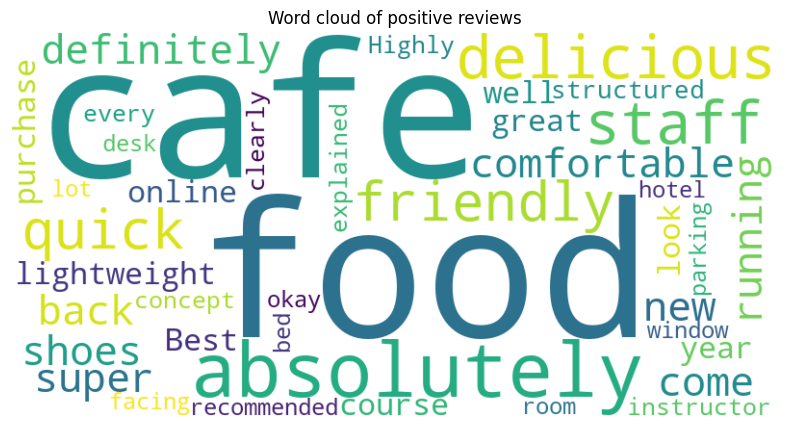

In [16]:
from wordcloud import WordCloud

positive_text = " ".join(r for r, s in zip(reviews, sent_df["sentiment"]) if s == "Positive")
wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=STOP, colormap="viridis").generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word cloud of positive reviews")
plt.show()

---
## Q6. Text generation with Keras (LSTM)
Training data: my own paragraph of about 100 words on space exploration.

In [17]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)
np.random.seed(42)

corpus = '''space exploration helps us understand our place in the universe.
rockets carry satellites and astronauts beyond the atmosphere of the earth.
the moon was the first world that humans visited outside our planet.
today scientists send robots to explore mars and study its red soil.
telescopes in space capture light from stars and galaxies far away.
every mission teaches us something new about the universe and about ourselves.
one day humans may live on mars and travel to distant stars.
space exploration inspires young students to study science and dream big.'''

print("Words in training text:", len(corpus.split()))

# 1. Tokenize
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus.split("\n"))
vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)
print("Sample word index:", dict(list(tokenizer.word_index.items())[:10]))

Words in training text: 91
Vocabulary size: 68
Sample word index: {'the': 1, 'and': 2, 'space': 3, 'to': 4, 'exploration': 5, 'us': 6, 'our': 7, 'in': 8, 'universe': 9, 'humans': 10}


In [18]:
# 2. Build n-gram input sequences per line
sequences = []
for line in corpus.split("\n"):
    ids = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(ids)):
        sequences.append(ids[: i + 1])

max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding="pre")
X, y = sequences[:, :-1], to_categorical(sequences[:, -1], num_classes=vocab_size)
print(f"Input sequences: {X.shape}, labels: {y.shape}")
print("Example:", X[5], "->", sequences[5, -1])

model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(128),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()

Input sequences: (83, 11), labels: (83, 68)
Example: [ 0  0  0  0  0  3  5 15  6 16  7] -> 17


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 11, 64)              │           4,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 128)                 │          98,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 68)                  │           8,772 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,940 (437.27 KB)

 Trainable params: 111,940 (437.27 KB)

 Non-trainable params: 0 (0.00 B)

Final loss: 0.1290   Final accuracy: 0.9880


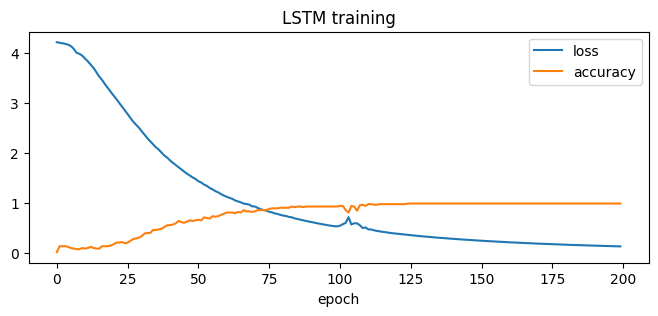

In [19]:
# 3. Train
history = model.fit(X, y, epochs=200, verbose=0)
print(f"Final loss: {history.history['loss'][-1]:.4f}   Final accuracy: {history.history['accuracy'][-1]:.4f}")

plt.figure(figsize=(8, 3))
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["accuracy"], label="accuracy")
plt.xlabel("epoch"); plt.legend(); plt.title("LSTM training")
plt.show()

In [20]:
index_word = {i: w for w, i in tokenizer.word_index.items()}

def generate(seed, n_words=10):
    text = seed
    for _ in range(n_words):
        ids = tokenizer.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding="pre")
        next_id = int(np.argmax(model.predict(ids, verbose=0)))
        text += " " + index_word.get(next_id, "")
    return text

for seed in ["space", "humans", "telescopes"]:
    print(f"Seed '{seed}': {generate(seed, 10)}")

Seed 'space': space exploration helps us understand our place in the universe universe
Seed 'humans': humans day humans may live on mars and travel to stars
Seed 'telescopes': telescopes in space capture light from stars and galaxies far away


**Notes:** the model learns word-to-word transitions from a very small corpus, so the generated lines mostly reproduce or recombine phrases from the training paragraph. It fits the training data almost perfectly but cannot produce truly new content. A larger corpus, temperature sampling instead of `argmax`, and dropout would give more varied text.